# One-dimensional periodic, elliptic, and parabolic correctors

Here $u$ is the **mean-zero periodic corrector**, $u_R$ is the **zero-Dirichlet elliptic corrector** on $K_R=(-R/2,R/2)$, and $u_{R,T}$ is the **zero-Dirichlet parabolic corrector** integrated up to time $T$.

Edit `a(x)` in the next cell to use any **positive, 1-periodic** coefficient. The notebook plots all three correctors, their derivatives and pointwise errors, an animation as $R$ varies, and $L^2$ and $H^1$ errors over the inner interval $K_L$. By default $L=R/(1+2\delta)$ with $\delta=0.25$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Edit this NumPy-vectorized, positive, 1-periodic coefficient.
# It is the first diagonal entry of PeriodicCoefficientProblem(epsilon=1).
def a(x):
    return 1.0 / (8.0 * np.pi**2 * (1.0 + 0.5 * np.cos(2.0 * np.pi * x)))

R_fixed = 4.5
delta = 0.25
R_values = np.linspace(1.0, 20.0, 381)
R_frames = np.linspace(1.0, 12.0, 36)
periods_to_show = 6            # span of the coefficient/corrector preview
period_grid_points = 4097       # quadrature points for the periodic primitive
plot_points = 1001              # points across K_R in fixed-R plots
error_points = 1201             # points across K_L in each error integral

# Default time from the repository settings at delta=0.25.
# Edit this function when trying a different time scaling or coefficient.
def T_of_R(R):
    return (4.0 * np.pi / 3.0) * R

parabolic_points_per_period = 256
max_time_step = 0.25
parabolic_time_integrator = "consistent"  # "consistent" or "repository"


## Periodic and finite-interval correctors

Let $a^*=(\int_0^1 a^{-1})^{-1}$. Numerical quadrature constructs the unique periodic corrector with $\int_0^1u=0$:

$$
u'(x)=\frac{a^*}{a(x)}-1,\qquad
u(x)=\int_0^x\left(\frac{a^*}{a(t)}-1\right)dt
-\int_0^1(1-t)\left(\frac{a^*}{a(t)}-1\right)dt.
$$

Set $d_R=u(R/2)-u(-R/2)$ and $s_R=[u(R/2)+u(-R/2)]/2$. Then

$$
u_R(x)=\frac{R[u(x)-s_R]-d_Rx}{R+d_R},\qquad
u_R'(x)=\frac{Ru'(x)-d_R}{R+d_R}.
$$

Thus $u_R$ needs no discrete boundary-value solve: this is the exact one-dimensional formula, up to numerical quadrature used to construct $u$.

In [2]:
period_x = np.linspace(0.0, 1.0, period_grid_points)
a_period = np.broadcast_to(np.asarray(a(period_x), dtype=float), period_x.shape)
if not np.all(np.isfinite(a_period)) or np.any(a_period <= 0):
    raise ValueError("a(x) must be finite and strictly positive on [0, 1].")
if not np.isclose(a_period[0], a_period[-1], rtol=1e-8, atol=1e-12):
    raise ValueError("a(x) must be 1-periodic: a(0) and a(1) differ.")

inverse_a = 1.0 / a_period
dx_period = period_x[1] - period_x[0]
primitive_inverse_a = np.concatenate((
    [0.0], np.cumsum(0.5 * (inverse_a[:-1] + inverse_a[1:]) * dx_period)
))
a_hom = 1.0 / primitive_inverse_a[-1]
primitive_u = a_hom * primitive_inverse_a - period_x
u_mean = np.trapezoid(primitive_u, period_x)

def u(x):
    """Mean-zero 1-periodic corrector, interpolated from the period grid."""
    phase = np.mod(np.asarray(x, dtype=float), 1.0)
    return np.interp(phase, period_x, primitive_u) - u_mean

def u_prime(x):
    x = np.asarray(x, dtype=float)
    return a_hom / a(x) - 1.0

def boundary_values(R):
    if R <= 0:
        raise ValueError("R must be positive.")
    plus, minus = u(R / 2), u(-R / 2)
    return plus - minus, 0.5 * (plus + minus)

def u_R(x, R):
    d, s = boundary_values(R)
    return (R * (u(x) - s) - d * np.asarray(x, dtype=float)) / (R + d)

def u_R_prime(x, R):
    d, _ = boundary_values(R)
    return (R * u_prime(x) - d) / (R + d)

print(f"Homogenized coefficient a* = {a_hom:.10g}")
print(f"Mean of u over one period = {np.trapezoid(u(period_x), period_x):.3e}")


Homogenized coefficient a* = 0.01266514796
Mean of u over one period = 6.939e-18


## Finite-interval parabolic corrector

The continuous formulation starts with $g=a'$ and solves

$$
\partial_t w_R-\partial_x(a\partial_x w_R)=0\quad\text{in }K_R,\qquad
w_R=0\quad\text{on }\partial K_R,\qquad w_R(0)=g,
$$

then sets $u_{R,T}=\int_0^T w_R(t)\,dt$. Spatial discretization below uses piecewise-linear finite elements and the weak initial load $\int g v=-\int a v'$. Time stepping uses backward Euler.

The default `parabolic_time_integrator="consistent"` computes the discrete identity $u_{R,T}^h=u_R^h-v^h(T)$, where $v^h$ is the backward-Euler heat evolution starting from the discrete elliptic corrector $u_R^h$. This approaches $u_R^h$ as $T\to\infty$. Set `parabolic_time_integrator="repository"` to reproduce the current code's backward-Euler values followed by trapezoidal time integration. That combination has a time-step bias: as $T\to\infty$, it approaches $u_R^h+(\Delta t/2)w_0^h$ rather than $u_R^h$. Rerun all cells after changing the setting.

`T_of_R(R)` is editable. Its default $T=4\pi R/3$ matches the repository's default time for the original coefficient and $\delta=0.25$; it is not an optimized choice for every user-defined coefficient. Both options approximate the continuous $u_{R,T}$.

In [3]:
from functools import lru_cache
from scipy.sparse import diags
from scipy.sparse.linalg import splu

@lru_cache(maxsize=128)
def parabolic_solution(R, T, integrator):
    """P1 FEM and backward Euler on K_R; selectable time integration."""
    R, T = float(R), float(T)
    if R <= 0 or T < 0:
        raise ValueError("R must be positive and T must be nonnegative.")
    cells = max(8, int(np.ceil(parabolic_points_per_period * R)))
    nodes = np.linspace(-R / 2, R / 2, cells + 1)
    h = R / cells
    values = np.zeros(cells + 1)
    if T == 0:
        return nodes, values

    midpoints = 0.5 * (nodes[:-1] + nodes[1:])
    gauss_offset = h / (2.0 * np.sqrt(3.0))
    cell_a = 0.5 * (
        np.asarray(a(midpoints - gauss_offset), dtype=float)
        + np.asarray(a(midpoints + gauss_offset), dtype=float)
    )
    cell_a = np.broadcast_to(cell_a, (cells,))
    if not np.all(np.isfinite(cell_a)) or np.any(cell_a <= 0):
        raise ValueError("a(x) must be finite and strictly positive on K_R.")

    interior = cells - 1
    mass = diags(
        [np.full(interior - 1, h / 6), np.full(interior, 2 * h / 3),
         np.full(interior - 1, h / 6)], [-1, 0, 1], format="csc"
    )
    stiffness = diags(
        [-cell_a[1:-1] / h, (cell_a[:-1] + cell_a[1:]) / h,
         -cell_a[1:-1] / h], [-1, 0, 1], format="csc"
    )
    # At an interior node: -int(a * hat_prime) = a_mean_right - a_mean_left.
    initial_rhs = cell_a[1:] - cell_a[:-1]
    steps = int(np.ceil(T / max_time_step))
    dt = T / steps
    step_solver = splu(mass + dt * stiffness)
    if integrator == "consistent":
        steady = splu(stiffness).solve(initial_rhs)
        residual = steady.copy()
        for _ in range(steps):
            residual = step_solver.solve(mass @ residual)
        values[1:-1] = steady - residual
    elif integrator == "repository":
        w = splu(mass).solve(initial_rhs)
        integral = 0.5 * dt * w.copy()
        for step in range(steps):
            w = step_solver.solve(mass @ w)
            integral += dt * (0.5 if step == steps - 1 else 1.0) * w
        values[1:-1] = integral
    else:
        raise ValueError("integrator must be 'consistent' or 'repository'.")
    return nodes, values

def u_R_T(x, R, T=None):
    if T is None:
        T = T_of_R(R)
    nodes, values = parabolic_solution(float(R), float(T), parabolic_time_integrator)
    return np.interp(np.asarray(x, dtype=float), nodes, values)

def u_R_T_prime(x, R, T=None):
    """Piecewise-constant derivative of the P1 parabolic corrector."""
    if T is None:
        T = T_of_R(R)
    nodes, values = parabolic_solution(float(R), float(T), parabolic_time_integrator)
    slopes = np.diff(values) / np.diff(nodes)
    indices = np.searchsorted(nodes, np.asarray(x, dtype=float), side="right") - 1
    return slopes[np.clip(indices, 0, len(slopes) - 1)]

print(f"At R={R_fixed:g}, the default time is T={T_of_R(R_fixed):.5g}.")


At R=4.5, the default time is T=18.85.


## Coefficient and correctors over several periods

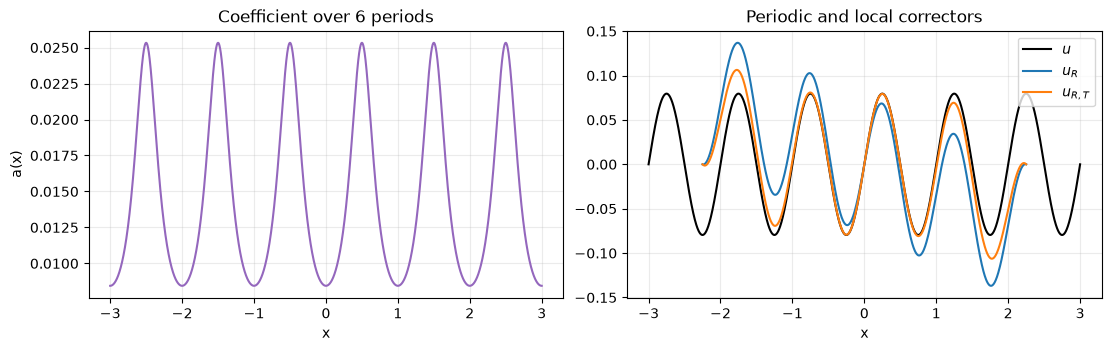

In [4]:
preview_x = np.linspace(-periods_to_show / 2, periods_to_show / 2,
                        600 * periods_to_show + 1)
local_x = np.linspace(-R_fixed / 2, R_fixed / 2, plot_points)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
axes[0].plot(preview_x, a(preview_x), color="tab:purple")
axes[0].set(title=f"Coefficient over {periods_to_show} periods", xlabel="x", ylabel="a(x)")
axes[1].plot(preview_x, u(preview_x), color="black", label=r"$u$")
axes[1].plot(local_x, u_R(local_x, R_fixed), color="tab:blue", label=r"$u_R$")
axes[1].plot(local_x, u_R_T(local_x, R_fixed), color="tab:orange", label=r"$u_{R,T}$")
axes[1].set(title="Periodic and local correctors", xlabel="x")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


## Fixed $R$: correctors, derivatives, and pointwise errors

Dashed vertical lines mark the endpoints of $K_L$. Curves are shown on all of $K_R$; the error norms below are integrated only over $K_L$. The parabolic derivative is piecewise constant because it comes from a piecewise-linear finite-element function.

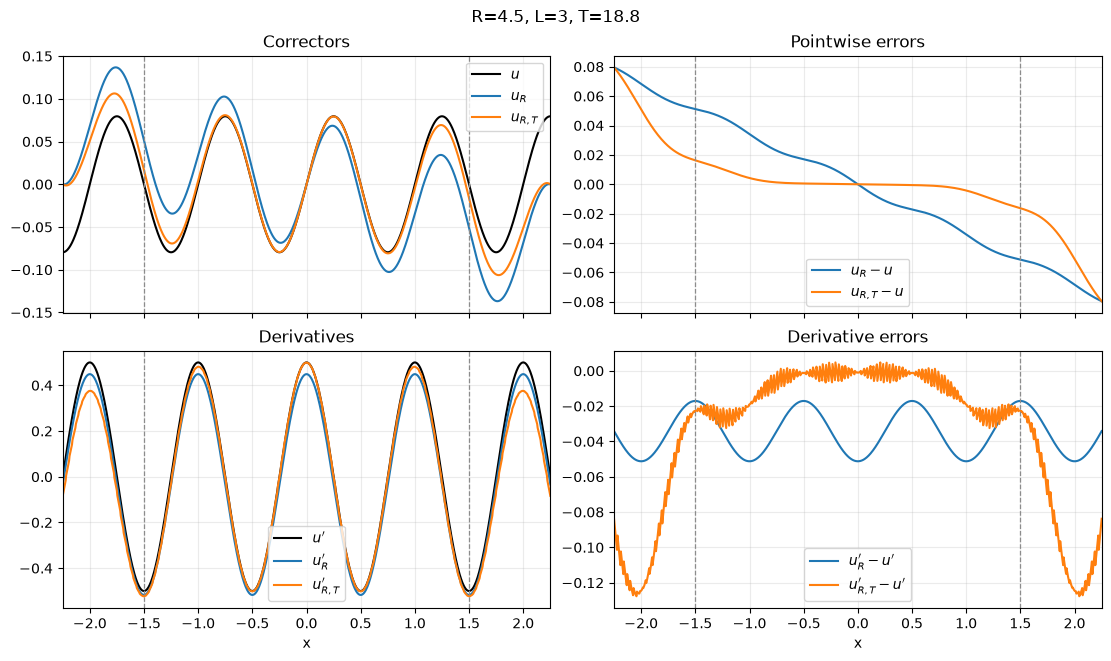

In [5]:
def profile(R, n=plot_points):
    x = np.linspace(-R / 2, R / 2, n)
    periodic = u(x)
    elliptic = u_R(x, R)
    parabolic = u_R_T(x, R)
    periodic_prime = u_prime(x)
    elliptic_prime = u_R_prime(x, R)
    parabolic_prime = u_R_T_prime(x, R)
    return (x, periodic, elliptic, parabolic,
            elliptic - periodic, parabolic - periodic,
            periodic_prime, elliptic_prime, parabolic_prime,
            elliptic_prime - periodic_prime, parabolic_prime - periodic_prime)

def mark_inner_interval(ax, R):
    L = R / (1.0 + 2.0 * delta)
    for edge in (-L / 2, L / 2):
        ax.axvline(edge, color="0.55", linestyle="--", linewidth=0.9)

def plot_fixed_R(R):
    data = profile(R)
    x = data[0]
    fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), constrained_layout=True, sharex=True)
    panels = [
        (axes[0, 0], [(1, r"$u$", "black"), (2, r"$u_R$", "tab:blue"),
                      (3, r"$u_{R,T}$", "tab:orange")], "Correctors"),
        (axes[0, 1], [(4, r"$u_R-u$", "tab:blue"),
                      (5, r"$u_{R,T}-u$", "tab:orange")], "Pointwise errors"),
        (axes[1, 0], [(6, r"$u'$", "black"), (7, r"$u_R'$", "tab:blue"),
                      (8, r"$u_{R,T}'$", "tab:orange")], "Derivatives"),
        (axes[1, 1], [(9, r"$u_R'-u'$", "tab:blue"),
                      (10, r"$u_{R,T}'-u'$", "tab:orange")], "Derivative errors"),
    ]
    for ax, curves, title in panels:
        for index, label, color in curves:
            ax.plot(x, data[index], color=color, label=label)
        mark_inner_interval(ax, R)
        ax.set(title=title, xlim=(-R / 2, R / 2))
        ax.grid(alpha=0.25)
        ax.legend(loc="best")
    axes[1, 0].set_xlabel("x")
    axes[1, 1].set_xlabel("x")
    fig.suptitle(f"R={R:g}, L={R / (1 + 2 * delta):.3g}, T={T_of_R(R):.3g}")
    plt.show()

plot_fixed_R(R_fixed)


## Animation as $R$ varies

All four comparison panels are updated as $R$ and $T(R)$ vary. Each frame shows the current $K_R$ on the horizontal axis; dashed vertical lines mark $K_L$. To export a GIF, uncomment `movie.save(...)` at the end of the animation cell.

In [6]:
def make_animation(R_sequence):
    frames = [profile(float(R), n=601) for R in R_sequence]
    fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
    panel_curves = [
        [(1, r"$u$", "black"), (2, r"$u_R$", "tab:blue"),
         (3, r"$u_{R,T}$", "tab:orange")],
        [(4, r"$u_R-u$", "tab:blue"), (5, r"$u_{R,T}-u$", "tab:orange")],
        [(6, r"$u'$", "black"), (7, r"$u_R'$", "tab:blue"),
         (8, r"$u_{R,T}'$", "tab:orange")],
        [(9, r"$u_R'-u'$", "tab:blue"),
         (10, r"$u_{R,T}'-u'$", "tab:orange")],
    ]
    titles = ["Correctors", "Pointwise errors", "Derivatives", "Derivative errors"]
    artists = []
    boundary_lines = []
    for ax, curves, title in zip(axes.flat, panel_curves, titles):
        lines = [ax.plot([], [], color=color, label=label)[0]
                 for _, label, color in curves]
        boundaries = [ax.axvline(0, color="0.55", linestyle="--", linewidth=0.9)
                      for _ in range(2)]
        all_y = np.concatenate([frame[index] for frame in frames for index, _, _ in curves])
        lo, hi = float(np.min(all_y)), float(np.max(all_y))
        pad = max(0.07 * (hi - lo), 1e-4)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set(title=title, xlabel="x")
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")
        artists.append(lines)
        boundary_lines.append(boundaries)

    def update(i):
        R = float(R_sequence[i])
        L = R / (1.0 + 2.0 * delta)
        frame = frames[i]
        for ax, curves, lines, boundaries in zip(axes.flat, panel_curves, artists, boundary_lines):
            for (index, _, _), line in zip(curves, lines):
                line.set_data(frame[0], frame[index])
            for edge, line in zip((-L / 2, L / 2), boundaries):
                line.set_xdata([edge, edge])
            ax.set_xlim(-R / 2, R / 2)
        fig.suptitle(f"R={R:.2f}, L={L:.2f}, T={T_of_R(R):.2f}")
        return [line for group in artists + boundary_lines for line in group]

    movie = FuncAnimation(fig, update, frames=len(frames), interval=160, blit=False)
    plt.close(fig)
    return movie

movie = make_animation(R_frames)
display(HTML(movie.to_jshtml(fps=6)))
# Optional GIF export (requires Pillow):
# movie.save("corrector_1d.gif", writer="pillow", fps=6)


## $L^2$ and $H^1$ errors versus $R$

For each method, the norms are computed over $K_L=(-L/2,L/2)$:

$$
E_{L^2}=\left(\int_{K_L}|u_{\mathrm{method}}-u|^2dx\right)^{1/2},\quad
E_{H^1\mathrm{semi}}=\left(\int_{K_L}|u_{\mathrm{method}}'-u'|^2dx\right)^{1/2},\quad
E_{H^1}=\sqrt{E_{L^2}^2+E_{H^1\mathrm{semi}}^2}.
$$

The elliptic and parabolic curves use the same $K_L$ at each $R$. The parabolic curve uses $T=T(R)$ from the first code cell. The parabolic $H^1$ error includes the piecewise-constant finite-element derivative. At fixed spatial resolution, this discretization error can eventually dominate the continuum error as $R$ grows; increase `parabolic_points_per_period` to check refinement. The displayed curve uses the selected time integrator from the first code cell.

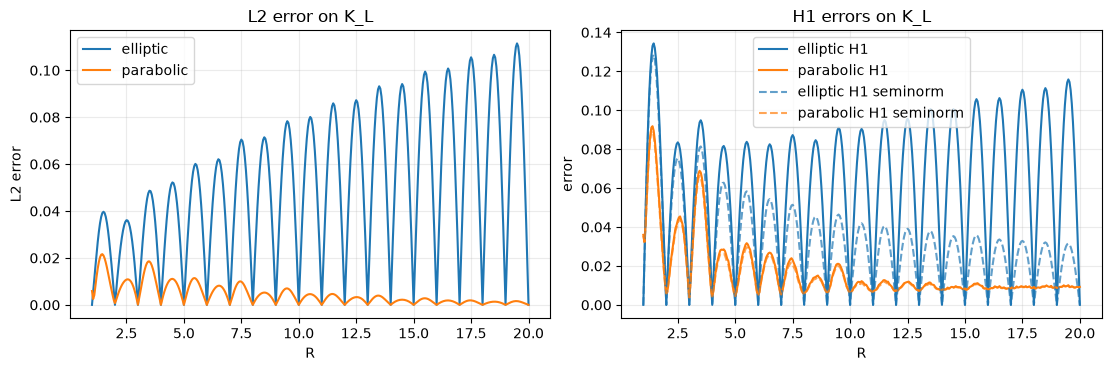

In [7]:
def errors_at_R(R, n=error_points):
    L = R / (1.0 + 2.0 * delta)
    n = max(n, int(np.ceil(4 * parabolic_points_per_period * L)) + 1)
    x = np.linspace(-L / 2, L / 2, n)
    periodic = u(x)
    periodic_prime = u_prime(x)
    elliptic_error = u_R(x, R) - periodic
    parabolic_error = u_R_T(x, R) - periodic
    elliptic_gradient_error = u_R_prime(x, R) - periodic_prime
    parabolic_gradient_error = u_R_T_prime(x, R) - periodic_prime
    elliptic_l2 = np.sqrt(np.trapezoid(elliptic_error**2, x))
    parabolic_l2 = np.sqrt(np.trapezoid(parabolic_error**2, x))
    elliptic_semi = np.sqrt(np.trapezoid(elliptic_gradient_error**2, x))
    parabolic_semi = np.sqrt(np.trapezoid(parabolic_gradient_error**2, x))
    return (elliptic_l2, parabolic_l2, elliptic_semi, parabolic_semi,
            np.hypot(elliptic_l2, elliptic_semi),
            np.hypot(parabolic_l2, parabolic_semi))

errors = np.array([errors_at_R(float(R)) for R in R_values])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].plot(R_values, errors[:, 0], color="tab:blue", label="elliptic")
axes[0].plot(R_values, errors[:, 1], color="tab:orange", label="parabolic")
axes[0].set(title="L2 error on K_L", ylabel="L2 error")
axes[1].plot(R_values, errors[:, 4], color="tab:blue", label="elliptic H1")
axes[1].plot(R_values, errors[:, 5], color="tab:orange", label="parabolic H1")
axes[1].plot(R_values, errors[:, 2], color="tab:blue", linestyle="--", alpha=0.7,
             label="elliptic H1 seminorm")
axes[1].plot(R_values, errors[:, 3], color="tab:orange", linestyle="--", alpha=0.7,
             label="parabolic H1 seminorm")
axes[1].set(title="H1 errors on K_L", ylabel="error")
for ax in axes:
    ax.set_xlabel("R")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()
